In [457]:
import os
import re
import glob
import copy
import enum
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

plt.close("all")

In [458]:
input_folder = "../build/cutsPower__2023-08-07T23-59-34"

In [459]:
tolerance: float = 0.000000000001
quantile: float = 0.99
max_value: float = 1000000000000000000.0

class CutType(enum.Enum):
    AllForce = "all(force)"
    All = "all"
    MySplit = "my(split)"
    MyMIR = "my(mir)"
    MySplitAll = "my(split)+all"
    MyMIRAll = "my(mir)+all"
    NoCuts = "none"
    Clique = "clique"
    Gomory = "gomory"
    MIR = "mir"
    LiftPr = "liftp"
    ZeroH = "zeroh"
    Disj = "disj"
    GUB = "gub"
    Cover = "cover"
    FlowC = "flowc"
    FlowP = "flowp"
    MCF = "mcf"
    ImplL = "impliedl"
    ImplG = "impliedg"

CutColors = {
CutType.AllForce.value : "green",
CutType.All.value : "green",
CutType.MySplit.value : "red",
CutType.MyMIR.value : "red",
CutType.MySplitAll.value : "green",
CutType.MyMIRAll.value : "green",
CutType.NoCuts.value : "black",
CutType.Clique.value : "blue",
CutType.Gomory.value : "blue",
CutType.MIR.value : "blue",
CutType.LiftPr.value : "blue",
CutType.ZeroH.value : "blue",
CutType.Disj.value : "blue",
CutType.GUB.value : "blue",
CutType.Cover.value : "blue",
CutType.FlowC.value : "blue",
CutType.FlowP.value : "blue",
CutType.MCF.value : "blue",
CutType.ImplL.value : "blue",
CutType.ImplG.value : "blue"
}

# CutColors = {
# CutType.AllForce.value : "g",
# CutType.All.value : "g",
# CutType.MySplit.value : "r",
# CutType.MyMIR.value : "r",
# CutType.MySplitAll.value : "g",
# CutType.MyMIRAll.value : "g",
# CutType.NoCuts.value : "b",
# CutType.Clique.value : "b",
# CutType.Gomory.value : "b",
# CutType.MIR.value : "b",
# CutType.LiftPr.value : "b",
# CutType.ZeroH.value : "b",
# CutType.Disj.value : "b",
# CutType.GUB.value : "b",
# CutType.Cover.value : "b",
# CutType.FlowC.value : "b",
# CutType.MCF.value : "b",
# CutType.ImplL.value : "b",
# CutType.ImplG.value : "b"
# }

class GroupType(enum.Enum):
    Cut = "cut_type"
    LPDiff = "lp_diff"
    MILPDiff = "milp_diff"
    CutoffDiff = "cutoff_diff"
    

In [460]:
cut_type_pattern = r"Cut-type =\s*\"(?P<" + GroupType.Cut.value + r">[^\"]+(?=\":))"
lp_diff_pattern = r"LP Diff. =\s*(?P<" + GroupType.LPDiff.value + r">[-+]*\d*\.*\d+([eE][-+]?\d+)?)"
milp_diff_pattern = r"MILP Diff. =\s*(?P<" + GroupType.MILPDiff.value + r">[-+]*\d*\.*\d+([eE][-+]?\d+)?)"
cutoff_diff_pattern = r"Cutoff Diff. =\s*(?P<" + GroupType.CutoffDiff.value + r">[-+]*\d*\.*\d+([eE][-+]?\d+)?)"

In [461]:
def parse_file(filename : str) -> {str : float}:
    results : {str : float} = {}
    lines_counter : int = 0
    with open(filename, "r") as file:
        for line in file:
            # if not line.strip(): 
            #     continue
            cut_type: str = ""
            lp_diff: float = 0.0 

            match = re.search(cut_type_pattern, line)
            if match:
                cut_type = match.groupdict()[GroupType.Cut.value]
            elif line != "\n":
                raise Exception(f"Can't math the cut type in {lines_counter}-th line of {filename}")

            match = re.search(lp_diff_pattern, line)
            if match:
                lp_diff = float(match.groupdict()[GroupType.LPDiff.value])
            elif line != "\n":
                raise Exception(f"Can't math the LP-diff in {lines_counter}-th line of {filename}")

            if cut_type != "":
                results[cut_type] = lp_diff

            lines_counter += 1

    return results

In [462]:
def make_patterns_list():
    # note: regex used for number with exponent: [-+]*\d*\.*\d+([eE][-+]?\d+)?
    pattern_cut_type = r"Cut-type =\s*\"(?P<" + GroupType.Cut + r">[^\"]+(?=\":))"
    pattern_lp_diff = r"LP Diff. =\s*(?P<" + GroupType.LPDiff + r">[-+]*\d*\.*\d+([eE][-+]?\d+)?)"
    pattern_milp_diff = r"MILP Diff. =\s*(?P<" + GroupType.MILPDiff + r">[-+]*\d*\.*\d+([eE][-+]?\d+)?)"
    pattern_cutoff_diff = r"Cutoff Diff. =\s*(?P<" + GroupType.CutoffDiff + r">[-+]*\d*\.*\d+([eE][-+]?\d+)?)"

    return (
        (pattern_cut_type, GroupType.Cut),
        (pattern_lp_diff, GroupType.LPDiff),
        (pattern_milp_diff, GroupType.MILPDiff),
        (pattern_cutoff_diff, GroupType.CutoffDiff)
    )

In [463]:
def parse_logs(logs_path: str) -> pd.DataFrame:
    
    problem_names : [str] = []
    df_rows : [{str : float}] = []

    for filename in glob.glob(f"{logs_path}/*gz_results.txt"):
        problem_name : str = re.search(r"(?<=/)[^/]+(?=.mps.gz_results.txt)", filename)[0]
        problem_names.append(problem_name)

        problem_data : {str : float} = parse_file(filename)

        df_rows.append(problem_data)

    return pd.DataFrame(df_rows, index=problem_names)

pure_data_df = parse_logs(input_folder)
# pure_data_df

In [464]:

filtered_df = pure_data_df.applymap(lambda x: x if x > tolerance and x < max_value else 0.0)
# filtered_df

In [465]:
# def make_quantile_filtering(df : pd.DataFrame) -> pd.DataFrame:
#     none_column = df[CutType.NoCuts.value]

# relative_df = make_relative_df(tolerance_filtered_df)

In [466]:
# plt.figure()

# tolerance_filtered_df.plot(figsize=(35,35), kind="bar")

# filtered_df.plot.bar(figsize=(40,400))

{'all(force)': 'green', 'all': 'green', 'my(split)': 'red', 'my(mir)': 'red', 'my(split)+all': 'green', 'my(mir)+all': 'green', 'none': 'black', 'clique': 'blue', 'gomory': 'blue', 'mir': 'blue', 'liftp': 'blue', 'zeroh': 'blue', 'disj': 'blue', 'gub': 'blue', 'cover': 'blue', 'flowc': 'blue', 'flowp': 'blue', 'mcf': 'blue', 'impliedl': 'blue', 'impliedg': 'blue'}
Index(['all', 'all(force)', 'clique', 'cover', 'disj', 'flowc', 'flowp',
       'gomory', 'gub', 'impliedg', 'impliedl', 'liftp', 'mcf', 'mir',
       'my(mir)', 'my(mir)+all', 'my(split)', 'my(split)+all', 'none',
       'zeroh'],
      dtype='object')


ValueError: Invalid RGBA argument: 'all(force)'

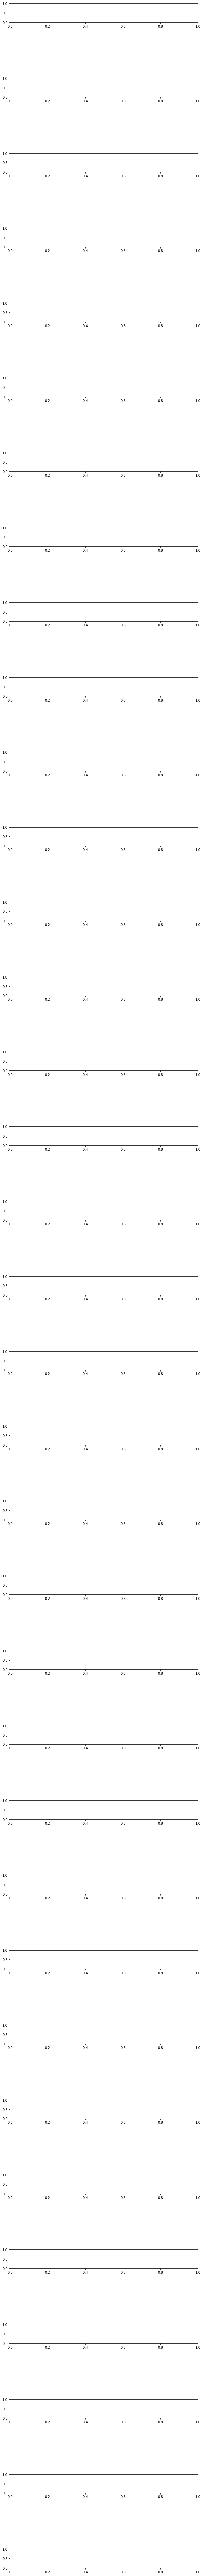

In [476]:
problems_number = len(filtered_df.index)
cut_types_num = len(CutType)

fig, axes = plt.subplots(nrows=problems_number, ncols=1, figsize=(0.5*cut_types_num, 4 * problems_number))

print(CutColors)
print(filtered_df.columns)

plt.subplots_adjust(wspace=0.2, hspace=3)

for i, name in enumerate(tolerance_filtered_df.index):
    # axes[i].set_title(name)
    # axes[i].margins(0.1)
    # axes[i].bar(, color=CutColors)
    tolerance_filtered_df.loc[name].plot.bar(ax=axes[i], sharex = False, sharey = False, color=CutColors, title = name)
    # filtered_df.loc[index].plot.bar()

# tolerance_filtered_df.iloc[3].plot.bar()

In [ ]:
def filter_data(result_dict, target_diff_column):
    for problem, data in list(result_dict.items()):
        if target_diff_column in data.columns:
            data = data.loc[(data[[target_diff_column]] != 0.0).all(axis=1), :]
            result_dict[problem] = data
            if not len(data):
                del result_dict[problem]
        else:
            del result_dict[problem]

def plot_report(result_dict_origin, target_diff=diff.lp_diff, hide_empty_columns=True, zero_none_cuts=False):
    """
    Plot plots for all problems from result_dict_origin for cuts: all, none, clique, my, my+all.
    For every problem, 2 charts are generated:
        * Bar chart which compare absolute value for every cut type
        * Bar chart which compare cut types difference in percent between none cut type and others.
          This chart is not drawn if none cut for current problem is None of 0
    Arguments:
        result_dict_origin: source dict with problem names as keys and dataframes with results as values
        target_diff: value of diff enum, what diff use: LP, MILP or Cutoff
        hide_empty_columns: if set to True, bars for cuts with empty values will be hidden
        zero_none_cuts: used when percent values are calculated. Ff True, none cuts will be considered as 0%, else 100%
    """
    result_dict = copy.deepcopy(result_dict_origin)
    target_diff_column = target_diff.value
    if hide_empty_columns:
        filter_data(result_dict, target_diff_column)

    if not len(result_dict.keys()):
        print(f"There are no problems for {target_diff}")
        return
    
    cuts =   ["all(force)", "all",   "my(split)",  "my(mir)",       "my(split)+all", "my(mir)+all", "none",  "clique", "gomory", "mir",  "liftp", "zeroh", "disj", "gub",  "cover", "flowc", "flowp", "mcf",  "impliedl", "impliedg"]
    colors = ["green",   "green", "red",        "red",           "green",         "green",         "black", "blue",   "blue",   "blue", "blue",  "blue",  "blue", "blue", "blue",  "blue",  "blue",  "blue", "blue",     "blue"]
    color_map = dict(zip(cuts, colors))

    colsize = 2
    coordinates = range(len(cuts))
    data_list = list(result_dict.items())
    none_cut = "none"
    margin = 0.1
    mantissa_len = 4
    text_offset_percent = 0.01   

    fig = plt.figure(constrained_layout=True, figsize=(35, 4 * len(result_dict.keys())))  # figsize=(width, height)
    fig.suptitle('Comparison of different cut types', fontsize='x-large', fontweight='bold')
    subfigs = fig.subfigures(nrows=len(result_dict.keys()), ncols=1, hspace=0.1)
    if len(result_dict) <= 1:
        subfigs = [subfigs]
    for row, subfig in enumerate(subfigs):
        problem_name, data = data_list[row]
        
        # Check if target cut type is presented in data (== cut type was presented in result file)
        if target_diff_column not in data.columns:
            continue

        cut_diff = data.loc[data[col_cut_type].isin(cuts)]
        cut_diff.reset_index(drop=True, inplace=True)
        coordinates = range(len(cut_diff))
        row_axs = subfig.subplots(nrows=1, ncols=colsize)

        # Diff Absolute
        ax = row_axs[0]
        lp_diff_colors = [color_map[c] for c in cut_diff[col_cut_type]]
        ax.bar(coordinates, cut_diff[target_diff_column].abs(), width=0.4, color=lp_diff_colors)  
        ax.set_xticks(coordinates)
        ax.set_xticklabels(cut_diff[col_cut_type])
        ax.set_title(target_diff_column + " absolute")
        for i, coordinate in enumerate(coordinates):
            ax.text(
                coordinate,
                cut_diff[target_diff_column][i] * (1 + text_offset_percent),
                cut_diff[target_diff_column][i],  # round(cut_diff[target_diff_column][i], mantissa_len),
                ha = 'center',
                # bbox = dict(facecolor = 'red', alpha =.7)
            )
        ax.margins(margin)

        # Diff Percent
        none_diff = cut_diff.loc[cut_diff[col_cut_type] == none_cut]
        if len(none_diff):
            none_diff = none_diff.iloc[0][target_diff_column]
        else:
            none_diff = None
        ax = row_axs[1]
        if none_diff:
            none_cut_percent = 0.2 if zero_none_cuts else 100  # in %
            diff_persent = cut_diff[target_diff_column].apply(lambda x: ((abs(x) - abs(none_diff)) / abs(none_diff)) * 100 + none_cut_percent)
            lp_percent_colors = [color_map[c] for c in cut_diff[col_cut_type]]
            ax.bar(coordinates, diff_persent, width=0.4, color=lp_percent_colors)
            ax.set_xticks(coordinates)
            ax.set_xticklabels(cut_diff[col_cut_type])
            ax.set_title(target_diff_column + " %")
            for i, coordinate in enumerate(coordinates):
                current_percent_diff = round(diff_persent[i] - none_cut_percent, mantissa_len)
                sign = ""
                if current_percent_diff < 0:
                    sign = "- "
                elif current_percent_diff > 0:
                    sign = "+ "
                label = sign + str(abs(current_percent_diff)) + "%"
                ax.text(
                    coordinate,
                    diff_persent[i] * (1 + text_offset_percent),
                    label,
                    ha = 'center',
                    # bbox = dict(facecolor = 'red', alpha =.7)
                )
            ax.margins(margin)
        else:
            # Do not plot in case if none cut diff is not presented in dataframe
            ax.axis('off')

        subfig.suptitle(problem_name)
    plt.show()

#### Plot for LP diff

In [ ]:
plot_report(result_dict, diff.lp_diff)

#### Plot for Cutoff diff

In [ ]:
# plot_report(result_dict, diff.cutoff_diff)